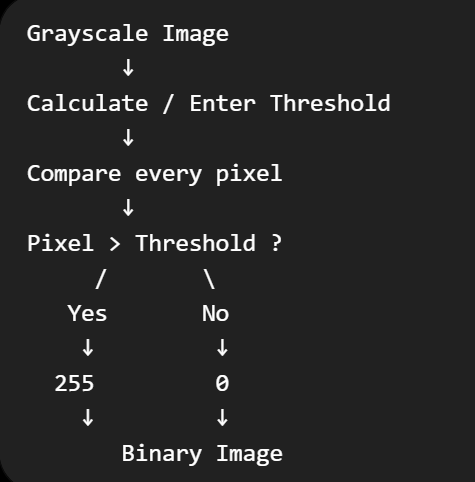

What exactly is a grayscale image?

 A grayscale image has only one intensity value per pixel.

| Intensity | Meaning     |
| --------: | ----------- |
|         0 | Black       |
|        50 | Dark gray   |
|       127 | Medium gray |
|       200 | Light gray  |
|       255 | White       |



What is a binary image?

A binary image has only two possible values:

0    → Black

255  → White

Why do we need thresholding?

Thresholding is a technique used to convert a grayscale image into a binary image by comparing each pixel intensity with a threshold value.


        Object
          ↓
     █████████
     █████████
-------------------
     Background

The object may have brighter pixels than the background.

Thresholding lets us separate them:

Original grayscale

        ↓
Thresholding

        ↓
Object vs Background

That's why thresholding is useful in:

Image segmentation

Object detection

Document processing

Character recognition

Medical images

Computer vision

Mean intensity

Mean = sum of all pixel intensities​/ no of pixels




Example ->

image ->

10  20  30

40  50  60

70  80  90

Threshold = 50

Pixel >= 50 → 255

Pixel < 50  → 0

Result:

0    0    0

0   255  255

255 255  255


In [ ]:
from PIL import Image

In [ ]:
img = Image.open("IRONMAN Poster Design.jpg").convert("L") # "L" means grayscale.

In [ ]:
width, height = img.size

pixels = list(img.getdata())

image = []

for i in range(height):
    row = []

    for j in range(width):
        row.append(pixels[i * width + j])

    image.append(row)

In [ ]:
image

In [ ]:
total = 0
count = 0

for row in image:
    for pixel in row:
        total = total + pixel
        count = count + 1

threshold = total / count

print("Mean intensity =", threshold)

In [ ]:
binary = []

for row in image:
    new_row = []

    for pixel in row:
        if pixel >= threshold:
            new_row.append(255)
        else:
            new_row.append(0)

    binary.append(new_row)

In [ ]:
binary_pixels = []

for row in binary:
    for pixel in row:
        binary_pixels.append(pixel)

In [ ]:
binary_image = Image.new("L", (width, height))

binary_image.putdata(binary_pixels)

display(binary_image)

Case 2 — User enters threshold

In [ ]:
threshold = int(input("Enter threshold value (0-255): "))

binary = []

for row in image:
    new_row = []

    for pixel in row:
        if pixel >= threshold:
            new_row.append(255)
        else:
            new_row.append(0)

    binary.append(new_row)

binary_pixels = []

for row in binary:
    for pixel in row:
        binary_pixels.append(pixel)

binary_image = Image.new("L", (width, height))
binary_image.putdata(binary_pixels)

print("Threshold =", threshold)

display(binary_image)

In [ ]:
# NOW DOING IT BY USING OPENCV

In [ ]:
import cv2

In [ ]:
print(cv2.__version__)

5.0.0


In [ ]:
img = cv2.imread("MF.jpg")

In [ ]:
# directly read it as grey scale image
img = cv2.imread("MF.jpg", cv2.IMREAD_GRAYSCALE)

In [ ]:
print(img.shape) # so image as 1200 rows and 675 columns so total 1200*675 = 8,10,000 pixels

(1200, 675)


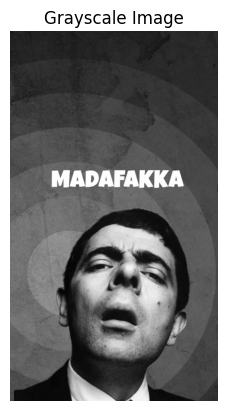

In [ ]:
import matplotlib.pyplot as plt

plt.imshow(img, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

In [ ]:
threshold = img.mean()

In [ ]:
print("Mean intensity =", threshold)

Mean intensity = 90.87492098765432


In [ ]:
threshold = int(img.mean())

In [ ]:
print("Threshold =", threshold)

Threshold = 90


In [ ]:
ret, binary = cv2.threshold(
    img,
    threshold,
    255,
    cv2.THRESH_BINARY
)
# ret -> the threshold that opencv used
# binary -> the resulting threshold image

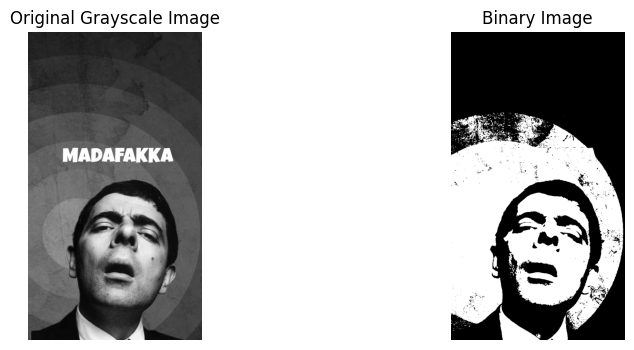

In [ ]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")

plt.show()

In [ ]:
# Case 2 taking threshold value from the user

Enter threshold value (0-255): 120
Threshold = 120


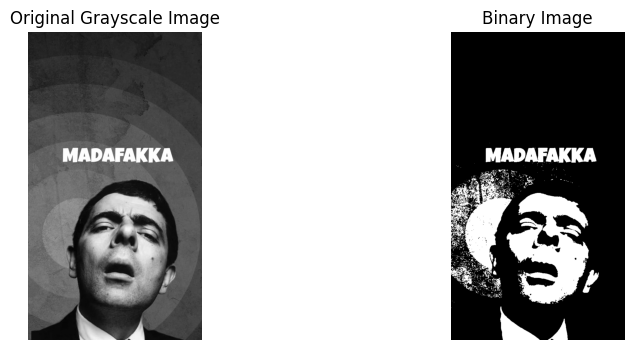

In [ ]:
threshold = int(input("Enter threshold value (0-255): "))

_, binary = cv2.threshold(
    img,
    threshold,
    255,
    cv2.THRESH_BINARY
)

print("Threshold =", threshold)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")

plt.show()